# Mamba — Selective State Space Models · Training

From-scratch, pure-PyTorch implementation of
**[Mamba: Linear-Time Sequence Modeling with Selective State Spaces](https://arxiv.org/abs/2312.00752)**
(Gu & Dao, 2023), trained as a character-level language model.
No `mamba-ssm`, no `causal-conv1d`, no `einops`.

### Architecture

6 Mamba blocks, $d_{\text{model}}=384$, $E=2 \Rightarrow d_{\text{inner}}=768$ —
**5.81 M parameters**. Per the paper (§3.4) two Mamba blocks replace one
(attention + MLP) Transformer layer, so this is ~a 3-layer Transformer's worth of depth.

```
embedding(65, 384)
  └─ 6 ×  ResidualBlock
            RMSNorm(384)
            in_proj:  384 → 1536          split → x (768) and gate z (768)
            Conv1d(768, 768, k=4, groups=768, causal)   ← depthwise, per-channel
            SiLU
            S6 selective scan              Δ,B,C = fn(x);  A (768×N_l);  D (768)
            × SiLU(z)                      the gate
            out_proj: 768 → 384
          + residual
  └─ RMSNorm(384) → lm_head 384 → 65  (tied to the embedding)
```

### The variation: a depth-varying state budget

The paper fixes $N=16$ in every layer. Here the *total* state is fixed instead —
$\sum_l N_l = 6 \times 16 = 96$ — and `state_schedule` decides how it is spread:

| `state_schedule` | $N$ per layer | $\sum N_l$ |
|---|---|---|
| `"constant"` (paper) | 16, 16, 16, 16, 16, 16 | 96 |
| `"linear"` | **5, 9, 13, 19, 23, 27** | 96 |

The hypothesis: early layers mostly do local work the depthwise conv already covers, so
their state is under-used, while the last layers are the ones that have to carry long-range
context. If so, moving state down the stack should buy accuracy for free.

*Free* is literal. Only `x_proj` ($d_{\text{inner}} \times (\text{dt\_rank} + 2N)$) and
`A_log` ($d_{\text{inner}} \times N$) depend on $N$, and both are **linear** in it — so any
schedule with the same sum has exactly the same parameter count (5,810,688), the same scan
FLOPs, the same $(B,L,D,N)$ activation bytes, and the same inference state (92,160 floats).
Nothing is traded; only placement changes. That makes it a clean A/B against the baseline.

One side effect to keep in mind: S4D-Real initialises $A = -1 \dots -N_l$, so a layer's $N$
also sets the *range* of its initial timescales. The ramp therefore gives deep layers a
wider spread (down to $-27$, i.e. some faster-decaying channels) rather than uniformly
slower memory. Both layers still get the slowest channel $A=-1$; the deep ones just get a
richer multi-scale basis. Whether that helps or hurts is part of what the run measures.

| Paper | Code |
|---|---|
| Eq. (1)–(2), (4) — ZOH discretization $\overline{A}=\exp(\Delta A)$ | `selective_scan_*` |
| **Algorithm 2** — S6: $\Delta, B, C$ become functions of $x$ | `SelectiveSSM` |
| §3.3.2 work-efficient parallel scan + kernel fusion | `selective_scan_chunked` + `torch.compile` |
| §3.4 the Mamba block (Figure 3) | `MambaBlock` |
| App. D recomputation instead of storing $(B,L,D,N)$ | gradient checkpointing |
| §3.6 S4D-Real init of $A$, log-uniform $\Delta$ | `SelectiveSSM.__init__` |
| *(departure)* per-layer $N$ at fixed budget | `state_dims` |

> Run this notebook first, then `02_mamba_inference.ipynb`. Checkpoints are named after the
> schedule, so `"constant"` and `"linear"` runs do not overwrite each other.

---
## 1 · Environment

Sized for a **6 GB laptop GPU** (RTX 4050, 14 GB RAM): peak VRAM stays under 2 GB.
The cell prints what it finds and §4 adapts to it.

In [1]:
import math, time, pathlib, platform, textwrap
import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd()
DATA_DIR = ROOT / "data"; DATA_DIR.mkdir(exist_ok=True)
CKPT_DIR = ROOT / "checkpoints"; CKPT_DIR.mkdir(exist_ok=True)

torch.manual_seed(1337)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AMP_DTYPE = torch.bfloat16 if (DEVICE == "cuda" and torch.cuda.is_bf16_supported()) else torch.float32
torch.backends.cuda.matmul.allow_tf32 = True
torch.set_float32_matmul_precision("high")

print(f"torch   : {torch.__version__} (cuda {torch.version.cuda})   python {platform.python_version()}")
if DEVICE == "cuda":
    p = torch.cuda.get_device_properties(0)
    TOTAL_VRAM_GB = p.total_memory / 2**30
    print(f"gpu     : {p.name}  |  {TOTAL_VRAM_GB:.1f} GiB, {torch.cuda.mem_get_info()[0]/2**30:.1f} GiB free"
          f"  |  {p.multi_processor_count} SMs, sm_{p.major}{p.minor}")
else:
    TOTAL_VRAM_GB = 0.0
    print("gpu     : none - training will be slow; shrink MAX_STEPS / D_MODEL in section 4")
print(f"amp     : {AMP_DTYPE}")

torch   : 2.14.1+cu130 (cuda 13.0)   python 3.14.4
gpu     : NVIDIA GeForce RTX 4050 Laptop GPU  |  5.6 GiB, 4.8 GiB free  |  20 SMs, sm_89
amp     : torch.bfloat16


---
## 2 · Data — Tiny Shakespeare, character level

1.1 MB, 65 distinct characters. Small enough to sit on the GPU as one tensor, so batching
is a gather of random offsets and costs nothing. Point `TEXT_PATH` at any UTF-8 `.txt` to
use your own corpus — vocab, model and checkpoint all follow.

In [2]:
import urllib.request

TEXT_PATH = DATA_DIR / "tinyshakespeare.txt"
if not TEXT_PATH.exists():
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt",
        TEXT_PATH)
text = TEXT_PATH.read_text(encoding="utf-8")
print(f"corpus  : {len(text):,} characters")
print(f"preview : {text[:100]!r}")

corpus  : 1,115,394 characters
preview : 'First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou'


---
## 3 · The model

Written out to **`mamba_model.py`** by the next cell, so the inference notebook imports the
exact same code — one source of truth.

### The selective scan

$$h_t = \overline{A}_t\,h_{t-1} + \overline{B}_t\,x_t,\qquad y_t = C_t h_t + D x_t,
\qquad \overline{A}_t=\exp(\Delta_t A)$$

Because $\Delta_t, B_t, C_t$ depend on the input (Algorithm 2) this is **not** a
convolution — it has to be scanned. The paper's answer (§3.3.2) is a *work-efficient
parallel associative scan*, which is what `selective_scan_chunked` implements: within a
chunk, a Hillis–Steele doubling pass absorbs offsets $1, 2, 4, \dots$, so
$\log_2(\text{chunk})$ passes replace `chunk` sequential steps.

The factor position $t$ applies to position $t-k$ is

$$\prod_{r=t-k+1}^{t}\overline{A}_r \;=\; \exp\!\big(a_t - a_{t-k}\big),
\qquad a_t=\textstyle\sum_{s\le t}\Delta_s A$$

a **difference of cumulative sums**. Since $A<0$ and $\Delta>0$ that difference is always
$\le 0$, so every multiplier lands in $(0,1]$ and nothing can overflow — whatever $\Delta$
and $A$ the model learns. (The seductive alternative,
$h_t=e^{a_t}(h_0+\sum_s e^{-a_s}\overline{B}_sx_s)$, is ~2× faster and *wrong*: $e^{-a_s}$
needs $e^{|\text{chunk decay}|}$, which leaves float32 range and NaNs the run.)

`selective_scan_seq` — the literal `for t in range(L)` recurrence — is kept as the ground
truth for §5.

### Memory

The scan's intermediates are $(B,L,D,N)$ ≈ **190 MB per tensor per layer**. The paper never
stores them and recomputes in the backward pass instead (App. D); the portable equivalent
is `torch.utils.checkpoint` around each block (`MambaLM.grad_checkpoint = True`). ~30% more
compute for a ~3× memory cut — the difference between fitting and OOM on 6 GB.

In [3]:
%%writefile mamba_model.py
"""
Mamba: Linear-Time Sequence Modeling with Selective State Spaces (Gu & Dao, 2023)
arXiv:2312.00752  --  single-file, pure-PyTorch implementation.

Generated by the `%%writefile` cell in `01_mamba_train.ipynb`, so the training notebook and
the inference notebook share one source of truth.

No custom CUDA kernels, no `mamba-ssm`, no `causal-conv1d`, no `einops`.

Paper map
---------
  Eq. (1)-(2)   continuous SSM  ->  discrete recurrence         `selective_scan_*`
  Eq. (4)       ZOH discretization  A_bar = exp(dt A)           `selective_scan_*`
  Algorithm 2   S6 = SSM + selection (dt, B, C are fn of x)     `SelectiveSSM`
  Section 3.3.2 work-efficient parallel scan, kernel fusion     `selective_scan_chunked`
  Section 3.4   Mamba block (H3 + gated MLP fused), Figure 3    `MambaBlock`
  Appendix D    recomputation instead of storing (B,L,D,N)      `MambaLM.grad_checkpoint`

The one deliberate departure from the paper: N may vary with depth under a fixed total
state budget (`MambaConfig.state_schedule`, see `state_dims`).  "constant" is the paper.
"""

from __future__ import annotations

import math
from dataclasses import dataclass, asdict
from typing import Optional

import torch
import torch.nn as nn
import torch.nn.functional as F


# --------------------------------------------------------------------------------------
# Config
# --------------------------------------------------------------------------------------
@dataclass
class MambaConfig:
    vocab_size: int = 65
    d_model: int = 384          # D  (model width)
    n_layer: int = 6            # number of Mamba blocks
    d_state: int = 16           # N  (mean SSM state dim; total budget = n_layer * d_state)
    d_conv: int = 4             # short causal conv width
    expand: int = 2             # E  (paper: "we always fix E = 2")
    dt_rank: int | str = "auto"  # ceil(D/16), the low-rank bottleneck of s_Delta
    dt_min: float = 1e-3        # Delta init range (log-uniform)
    dt_max: float = 1e-1
    scan_chunk: int = 8         # doubling-scan chunk: log2(chunk) passes per chunk
    state_schedule: str = "constant"   # how the state budget is spread over depth

    def __post_init__(self):
        if self.dt_rank == "auto":
            self.dt_rank = math.ceil(self.d_model / 16)
        self.d_inner = int(self.expand * self.d_model)
        self.d_states = state_dims(self.n_layer, self.d_state, self.state_schedule)

    def to_dict(self):
        return asdict(self)

    @staticmethod
    def from_dict(d: dict) -> "MambaConfig":
        fields = set(MambaConfig.__dataclass_fields__)
        return MambaConfig(**{k: v for k, v in d.items() if k in fields})


def state_dims(n_layer: int, d_state: int, kind: str = "constant") -> list[int]:
    """Per-layer N under a *fixed total state budget* of `n_layer * d_state`.

      "constant"  every layer gets N = d_state.  The paper's setting (N = 16 throughout).
      "linear"    N grows linearly with depth, N_l ~ (l + 1), rescaled to spend exactly the
                  same budget:  n_layer=6, d_state=16  ->  [5, 9, 13, 19, 23, 27], sum 96.

    Only `x_proj` (d_inner x (dt_rank + 2N)) and `A_log` (d_inner x N) depend on N, and both
    are linear in it, so any schedule with the same sum has the *same* parameter count and
    the same scan FLOPs/activation bytes as the constant baseline -- the schedule is a pure
    reallocation, which is what makes it a clean A/B.
    """
    if kind == "constant":
        return [d_state] * n_layer
    if kind != "linear":
        raise ValueError(f"unknown state_schedule {kind!r}")

    # Round the *cumulative* ramp, then difference it: keeps the total exactly on budget
    # (plain per-layer rounding does not) and stays monotonically increasing.
    budget, w = n_layer * d_state, n_layer * (n_layer + 1) / 2
    cum = [round(budget * (l + 1) * (l + 2) / 2 / w) for l in range(n_layer)]
    dims = [cum[0]] + [cum[l] - cum[l - 1] for l in range(1, n_layer)]
    if min(dims) < 1:
        raise ValueError(f"state budget {budget} is too small for {n_layer} linear layers")
    return dims


# --------------------------------------------------------------------------------------
# Norm
# --------------------------------------------------------------------------------------
class RMSNorm(nn.Module):
    def __init__(self, d: int, eps: float = 1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(d))

    def forward(self, x):
        dtype = x.dtype
        x = x.float()
        x = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)
        return (x * self.weight.float()).to(dtype)


# --------------------------------------------------------------------------------------
# The selective scan
# --------------------------------------------------------------------------------------
# Shapes:  u (B,L,D)   delta (B,L,D)   A (D,N)   B_,C_ (B,L,N)   D_ (D,)   z (B,L,D)
#
#   A_bar_t = exp(delta_t * A)                                  (Eq. 4, ZOH)
#   B_bar_t  u_t  ~=  delta_t * B_t * u_t                       (as in the official code)
#   h_t = A_bar_t h_{t-1} + B_bar_t u_t                         (Eq. 2a)
#   y_t = C_t h_t + D u_t                                       (Eq. 2b + skip)
#   out = y * silu(z)                                           (gate, Section 3.4)


def selective_scan_seq(u, delta, A, B_, C_, D_, z=None):
    """Literal time-stepped recurrence. Slow but exact -- the reference for the tests."""
    b, l, d = u.shape
    u, delta, B_, C_, A = u.float(), delta.float(), B_.float(), C_.float(), A.float()

    dA = torch.exp(delta.unsqueeze(-1) * A)                        # (B,L,D,N)
    dBu = delta.unsqueeze(-1) * B_.unsqueeze(2) * u.unsqueeze(-1)   # (B,L,D,N)

    h = u.new_zeros(b, d, A.shape[1])
    ys = []
    for t in range(l):
        h = dA[:, t] * h + dBu[:, t]
        ys.append(torch.einsum("bdn,bn->bd", h, C_[:, t]))
    y = torch.stack(ys, dim=1) + u * D_.float()
    return y * F.silu(z.float()) if z is not None else y


def selective_scan_chunked(u, delta, A, B_, C_, D_, z=None, chunk: int = 8):
    """Chunk-parallel work-efficient associative scan -- the fast path.

    `h_t = A_bar_t h_{t-1} + dBu_t` is an associative scan, so it parallelises (Section
    3.3.2).  Within a chunk we run a Hillis-Steele doubling scan: after absorbing offsets
    1, 2, 4, ... each position has accumulated all of its predecessors, so log2(chunk)
    passes replace `chunk` sequential steps.  Chunks are then stitched together in order.

    The factor position t applies to position t-k is

        prod_{r=t-k+1..t} A_bar_r = exp(a_t - a_{t-k}),   a_t = cumsum_{s<=t}(delta_s A)

    a *difference of cumulative sums*.  Since A < 0 and delta > 0 that difference is always
    <= 0, so every multiplier lands in (0, 1] and nothing can overflow -- whatever delta and
    A the model learns.
    """
    b, l, d = u.shape
    u, delta, B_, C_, A = u.float(), delta.float(), B_.float(), C_.float(), A.float()

    dA_log = delta.unsqueeze(-1) * A                                # (B,L,D,N), <= 0
    dBu = delta.unsqueeze(-1) * B_.unsqueeze(2) * u.unsqueeze(-1)    # (B,L,D,N)

    h = u.new_zeros(b, d, A.shape[1])
    ys = []
    for s in range(0, l, chunk):
        e = min(s + chunk, l)
        a = torch.cumsum(dA_log[:, s:e], dim=1)                     # (B,c,D,N), <= 0
        acc = dBu[:, s:e]
        step = 1
        while step < e - s:
            # shift by `step` along time; positions < step get decay 0 / value 0 (no-ops)
            a_sh = F.pad(a[:, :-step], (0, 0, 0, 0, step, 0))
            acc_sh = F.pad(acc[:, :-step], (0, 0, 0, 0, step, 0))
            acc = torch.exp(a - a_sh) * acc_sh + acc
            step *= 2
        hs = torch.exp(a) * h.unsqueeze(1) + acc                    # (B,c,D,N)
        ys.append(torch.einsum("bcdn,bcn->bcd", hs, C_[:, s:e]))
        h = hs[:, -1]
    y = torch.cat(ys, dim=1) + u * D_.float()
    return y * F.silu(z.float()) if z is not None else y


# `torch.compile` fuses the long elementwise chain (exp / mul / cumsum / pad) into a handful
# of Triton kernels -- our stand-in for the paper's hand-written fused CUDA kernel: same
# idea, far fewer HBM round-trips.  The chunk loop is unrolled at trace time, so the
# compiled artefact is specific to one sequence length.
_scan = selective_scan_chunked


def compile_scan(enable: bool = True):
    """Compile (or restore) the scan. Call once before training."""
    global _scan
    _scan = torch.compile(selective_scan_chunked, dynamic=False) if enable \
        else selective_scan_chunked


# --------------------------------------------------------------------------------------
# S6 layer  (Algorithm 2)
# --------------------------------------------------------------------------------------
class SelectiveSSM(nn.Module):
    """dt / B / C are produced from the input -> time-varying, "selective" SSM."""

    def __init__(self, cfg: MambaConfig, d_state: int):
        super().__init__()
        self.cfg = cfg
        self.d_state = d_state                     # this layer's N (see `state_dims`)
        d_in, n, r = cfg.d_inner, d_state, cfg.dt_rank

        self.x_proj = nn.Linear(d_in, r + 2 * n, bias=False)   # x -> (dt_low_rank, B, C)
        self.dt_proj = nn.Linear(r, d_in, bias=True)           # Broadcast_D(Linear_1(x))

        # dt init (reference implementation): softplus(bias) log-uniform in [dt_min, dt_max]
        nn.init.uniform_(self.dt_proj.weight, -(r**-0.5), r**-0.5)
        dt = torch.exp(
            torch.rand(d_in) * (math.log(cfg.dt_max) - math.log(cfg.dt_min))
            + math.log(cfg.dt_min)
        ).clamp(min=1e-4)
        with torch.no_grad():
            self.dt_proj.bias.copy_(dt + torch.log(-torch.expm1(-dt)))  # inverse softplus
        self.dt_proj.bias._no_reinit = True

        # A: S4D-Real init, stored as a log so that A = -exp(A_log) stays negative
        self.A_log = nn.Parameter(torch.log(torch.arange(1, n + 1, dtype=torch.float32).repeat(d_in, 1)))
        self.A_log._no_weight_decay = True

        self.D = nn.Parameter(torch.ones(d_in))                # per-channel skip
        self.D._no_weight_decay = True

    def _project(self, x):
        n = self.d_state
        dt, B_, C_ = torch.split(self.x_proj(x), [self.cfg.dt_rank, n, n], -1)
        return F.softplus(self.dt_proj(dt)), B_, C_            # dt > 0

    def forward(self, x, z):
        A = -torch.exp(self.A_log.float())                     # (D,N), negative real
        dt, B_, C_ = self._project(x)
        return _scan(x, dt, A, B_, C_, self.D, z, chunk=self.cfg.scan_chunk)

    def step(self, x_t, ssm_state):
        """x_t (B,D) -> y_t (B,D); O(1) time and memory per token."""
        A = -torch.exp(self.A_log.float())                     # (D,N)
        dt, B_, C_ = self._project(x_t)
        dt, x32 = dt.float(), x_t.float()

        dA = torch.exp(dt.unsqueeze(-1) * A)                   # (B,D,N)
        dBx = dt.unsqueeze(-1) * B_.float().unsqueeze(1) * x32.unsqueeze(-1)
        ssm_state = ssm_state * dA + dBx
        y = torch.einsum("bdn,bn->bd", ssm_state, C_.float()) + x32 * self.D.float()
        return y, ssm_state


# --------------------------------------------------------------------------------------
# Mamba block  (Figure 3, right)
# --------------------------------------------------------------------------------------
class MambaBlock(nn.Module):
    """in_proj -> (conv -> silu -> S6) * silu(gate) -> out_proj"""

    def __init__(self, cfg: MambaConfig, d_state: int):
        super().__init__()
        self.cfg = cfg
        self.d_state = d_state
        d_in = cfg.d_inner
        self.in_proj = nn.Linear(cfg.d_model, 2 * d_in, bias=False)
        self.conv1d = nn.Conv1d(d_in, d_in, cfg.d_conv, groups=d_in, padding=cfg.d_conv - 1)
        self.ssm = SelectiveSSM(cfg, d_state)
        self.out_proj = nn.Linear(d_in, cfg.d_model, bias=False)

    def forward(self, u):
        l = u.shape[1]
        x, z = self.in_proj(u).chunk(2, dim=-1)                       # (B,L,d_inner) each
        x = self.conv1d(x.transpose(1, 2))[..., :l].transpose(1, 2)   # causal
        y = self.ssm(F.silu(x), z)
        return self.out_proj(y.to(u.dtype))

    def step(self, u_t, conv_state, ssm_state):
        """u_t (B,d_model); conv_state (B,d_inner,d_conv); ssm_state (B,d_inner,N)."""
        x, z = self.in_proj(u_t).chunk(2, dim=-1)                     # (B,d_inner)
        # slide the conv window: drop the oldest input, append the newest
        conv_state = torch.cat([conv_state[..., 1:], x.unsqueeze(-1).to(conv_state.dtype)], -1)
        x = (conv_state * self.conv1d.weight.squeeze(1)).sum(-1) + self.conv1d.bias
        y, ssm_state = self.ssm.step(F.silu(x), ssm_state)
        y = y * F.silu(z.float())
        return self.out_proj(y.to(u_t.dtype)), conv_state, ssm_state

    def allocate_cache(self, batch, device):
        return (torch.zeros(batch, self.cfg.d_inner, self.cfg.d_conv, device=device),
                torch.zeros(batch, self.cfg.d_inner, self.d_state, device=device))


class ResidualBlock(nn.Module):
    """Pre-norm residual wrapper (Section 3.4: block + norm + residual, repeated)."""

    def __init__(self, cfg: MambaConfig, d_state: int):
        super().__init__()
        self.norm = RMSNorm(cfg.d_model)
        self.mixer = MambaBlock(cfg, d_state)

    def forward(self, x):
        return x + self.mixer(self.norm(x))

    def step(self, x_t, conv_state, ssm_state):
        y, conv_state, ssm_state = self.mixer.step(self.norm(x_t), conv_state, ssm_state)
        return x_t + y, conv_state, ssm_state


# --------------------------------------------------------------------------------------
# Language model
# --------------------------------------------------------------------------------------
class MambaLM(nn.Module):
    def __init__(self, cfg: MambaConfig):
        super().__init__()
        self.cfg = cfg
        self.embedding = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.layers = nn.ModuleList([ResidualBlock(cfg, n) for n in cfg.d_states])
        self.norm_f = RMSNorm(cfg.d_model)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.lm_head.weight = self.embedding.weight            # tied
        self.grad_checkpoint = False

        self.apply(self._init_weights)
        for name, p in self.named_parameters():                # residual-branch rescaling
            if name.endswith("out_proj.weight"):
                nn.init.normal_(p, std=0.02 / math.sqrt(2 * cfg.n_layer))

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, std=0.02)
            if m.bias is not None and not getattr(m.bias, "_no_reinit", False):
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, std=0.02)

    def num_parameters(self, non_embedding: bool = False) -> int:
        n = sum(p.numel() for p in self.parameters())
        return n - self.embedding.weight.numel() if non_embedding else n

    def state_floats(self) -> int:
        """Recurrent state carried per sequence: conv windows + SSM states, all layers.

        Summed rather than `n_layer *` one layer, because N can vary with depth.
        """
        return sum(self.cfg.d_inner * (self.cfg.d_conv + m.mixer.d_state) for m in self.layers)

    def forward(self, idx, targets: Optional[torch.Tensor] = None):
        x = self.embedding(idx)
        for layer in self.layers:
            if self.grad_checkpoint and self.training:
                x = torch.utils.checkpoint.checkpoint(layer, x, use_reentrant=False)
            else:
                x = layer(x)
        logits = self.lm_head(self.norm_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)).float(), targets.reshape(-1))
        return logits, loss

    # ---------------- O(1)-per-token recurrent inference ----------------
    def allocate_cache(self, batch: int, device):
        return [layer.mixer.allocate_cache(batch, device) for layer in self.layers]

    def step(self, idx_t, cache):
        """idx_t (B,) -> logits (B,vocab). Constant memory, constant time."""
        x = self.embedding(idx_t)
        new_cache = []
        for layer, (conv_state, ssm_state) in zip(self.layers, cache):
            x, conv_state, ssm_state = layer.step(x, conv_state, ssm_state)
            new_cache.append((conv_state, ssm_state))
        return self.lm_head(self.norm_f(x)), new_cache

    @torch.inference_mode()
    def generate(self, prompt_ids, max_new_tokens=200, temperature=0.8, top_k=40,
                 callback=None):
        """prompt_ids (B,T) -> (B, T+max_new_tokens)."""
        self.eval()
        cache = self.allocate_cache(prompt_ids.shape[0], prompt_ids.device)
        for t in range(prompt_ids.shape[1]):          # warm the state up on the prompt
            logits, cache = self.step(prompt_ids[:, t], cache)
        out = [prompt_ids]
        for _ in range(max_new_tokens):
            nxt = sample(logits, temperature, top_k)
            out.append(nxt.unsqueeze(1))
            if callback is not None:
                callback(nxt)
            logits, cache = self.step(nxt, cache)
        return torch.cat(out, dim=1)


def sample(logits, temperature=1.0, top_k=None):
    logits = logits.float()
    if temperature <= 0:
        return logits.argmax(dim=-1)                  # greedy
    logits = logits / temperature
    if top_k:
        kth = logits.topk(min(top_k, logits.size(-1)), dim=-1).values[..., -1, None]
        logits = logits.masked_fill(logits < kth, float("-inf"))
    return torch.multinomial(logits.softmax(dim=-1), 1).squeeze(-1)


# --------------------------------------------------------------------------------------
# Character tokenizer
# --------------------------------------------------------------------------------------
class CharTokenizer:
    def __init__(self, chars):
        self.chars = list(chars)
        self.stoi = {c: i for i, c in enumerate(self.chars)}

    @classmethod
    def from_text(cls, text: str) -> "CharTokenizer":
        return cls(sorted(set(text)))

    @property
    def vocab_size(self) -> int:
        return len(self.chars)

    def encode(self, s: str):
        return [self.stoi[c] for c in s if c in self.stoi]

    def decode(self, ids) -> str:
        return "".join(self.chars[int(i)] for i in ids)

    def to_dict(self):
        return {"chars": self.chars}

    @staticmethod
    def from_dict(d):
        return CharTokenizer(d["chars"])

Overwriting mamba_model.py


In [4]:
import importlib, mamba_model
importlib.reload(mamba_model)
from mamba_model import (MambaConfig, MambaLM, CharTokenizer, state_dims,
                         selective_scan_seq, selective_scan_chunked, compile_scan)

tokenizer = CharTokenizer.from_text(text)
data = torch.tensor(tokenizer.encode(text), dtype=torch.long)
n_train = int(0.9 * len(data))
train_data, val_data = data[:n_train].to(DEVICE), data[n_train:].to(DEVICE)

print(f"vocab   : {tokenizer.vocab_size}  {''.join(tokenizer.chars)!r}")
print(f"train/val: {len(train_data):,} / {len(val_data):,} tokens "
      f"({data.element_size()*len(data)/2**20:.1f} MiB on {DEVICE})")

vocab   : 65  "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
train/val: 1,003,854 / 111,540 tokens (8.5 MiB on cuda)


---
## 4 · Configuration

Shapes follow the paper where it is prescriptive: $E=2$ (*"we always fix E = 2"*, §3.4),
$d_{\text{conv}}=4$, $\text{dt\_rank}=\lceil d_{\text{model}}/16\rceil$.

`d_state` is now read as the **mean** $N$: the budget is `n_layer * d_state` and
`state_schedule` distributes it. Set `STATE_SCHEDULE = "constant"` to get the paper's
uniform $N=16$ back — that is the baseline this variation is measured against, and the two
runs are identical in every other respect (same parameters, same FLOPs, same seed, same
schedule).

`BATCH_SIZE` / `GRAD_ACCUM` are the hardware knobs; their product × `SEQ_LEN` is the
effective tokens per optimizer step, held constant across tiers so the learning dynamics
do not change with your GPU.

In [ ]:
if TOTAL_VRAM_GB >= 20:      D_MODEL, N_LAYER, BATCH_SIZE, GRAD_ACCUM = 512, 8, 64, 1
elif TOTAL_VRAM_GB >= 10:    D_MODEL, N_LAYER, BATCH_SIZE, GRAD_ACCUM = 384, 6, 32, 1
elif TOTAL_VRAM_GB >= 5:     D_MODEL, N_LAYER, BATCH_SIZE, GRAD_ACCUM = 384, 6, 16, 2  # RTX 4050
elif TOTAL_VRAM_GB > 0:      D_MODEL, N_LAYER, BATCH_SIZE, GRAD_ACCUM = 256, 4,  8, 4
else:                        D_MODEL, N_LAYER, BATCH_SIZE, GRAD_ACCUM = 128, 2,  8, 1

SEQ_LEN = 256
STATE_SCHEDULE = "linear"                # "constant" = the paper's uniform N; "linear" = ramp
SEED = 1337                              # fixed so the two schedules are comparable

torch.manual_seed(SEED)
cfg = MambaConfig(vocab_size=tokenizer.vocab_size, d_model=D_MODEL, n_layer=N_LAYER,
                  d_state=16, d_conv=4, expand=2, scan_chunk=8,
                  state_schedule=STATE_SCHEDULE)

MAX_STEPS, WARMUP_STEPS = 1000, 150      # ~30 min on an RTX 4050; raise for a better model
LR, MIN_LR = 3e-3, 3e-4                  # small char-level model tolerates a high LR
WEIGHT_DECAY, GRAD_CLIP = 0.1, 1.0
EVAL_EVERY, EVAL_BATCHES = 100, 20

tokens_per_step = BATCH_SIZE * GRAD_ACCUM * SEQ_LEN
model = MambaLM(cfg).to(DEVICE)
model.grad_checkpoint = DEVICE == "cuda"
n_params = model.num_parameters()
scan_bytes = BATCH_SIZE * SEQ_LEN * cfg.d_inner * sum(cfg.d_states) * 4

print(textwrap.dedent(f'''
    model     d_model={cfg.d_model}  n_layer={cfg.n_layer}  d_inner={cfg.d_inner}
              dt_rank={cfg.dt_rank}  d_conv={cfg.d_conv}
    state     schedule={cfg.state_schedule!r}  N per layer = {cfg.d_states}
              total budget = {sum(cfg.d_states)} (= n_layer x d_state = {cfg.n_layer} x {cfg.d_state})
    params    {n_params:,} = {n_params/1e6:.2f} M   ({n_params*12/2**20:.0f} MiB incl. adam states)
              identical for every schedule with this budget - a pure reallocation
    batching  micro={BATCH_SIZE} x accum={GRAD_ACCUM} x seq={SEQ_LEN} = {tokens_per_step:,} tokens/step
    schedule  {MAX_STEPS} steps -> {MAX_STEPS*tokens_per_step/1e6:.1f}M tokens
              ({MAX_STEPS*tokens_per_step/len(train_data):.1f} epochs)
    memory    grad_checkpoint={model.grad_checkpoint}  amp={AMP_DTYPE}
              (B,L,D,N) scan tensors = {scan_bytes/2**20:.0f} MiB each, summed over layers
''').strip())

# the budget is identical whichever way it is spread - this is the control for the A/B
assert model.num_parameters() == MambaLM(MambaConfig(
    vocab_size=tokenizer.vocab_size, d_model=D_MODEL, n_layer=N_LAYER,
    state_schedule="constant")).num_parameters()

model     d_model=384  n_layer=6  d_state=16
          d_inner=768  dt_rank=24  d_conv=4
params    5.81 M   (66 MiB incl. adam states)
batching  micro=16 x accum=2 x seq=256 = 8,192 tokens/step
schedule  2000 steps -> 16.4M tokens
          (16.3 epochs)
memory    grad_checkpoint=True  amp=torch.bfloat16
          (B,L,D,N) scan tensor = 192 MiB each


---
## 5 · Correctness tests

Before burning GPU-time, prove the fast path is the same function as the slow one, and that
the training path is the same model as the O(1) inference path.

In [6]:
import torch.nn.functional as F

def test_scan(b=2, l=97, d=64, n=27, tol=1e-4):
    # chunked associative scan vs. the literal recurrence - forward AND backward
    g = torch.Generator(device=DEVICE).manual_seed(0)
    mk = lambda *s: torch.randn(*s, device=DEVICE, generator=g)
    args = (mk(b, l, d).requires_grad_(),
            (F.softplus(mk(b, l, d) - 2)).detach().requires_grad_(),
            (-torch.exp(torch.rand(d, n, device=DEVICE, generator=g) * 2)).requires_grad_(),
            mk(b, l, n).requires_grad_(), mk(b, l, n).requires_grad_(),
            torch.ones(d, device=DEVICE, requires_grad=True), mk(b, l, d).requires_grad_())
    y_ref = selective_scan_seq(*args)
    g_ref = torch.autograd.grad(y_ref.square().mean(), args)
    for chunk in (4, 8, 16, 32, 64, 128):
        y = selective_scan_chunked(*args, chunk=chunk)
        g_new = torch.autograd.grad(y.square().mean(), args)
        fwd = (y - y_ref).abs().max().item()
        bwd = max((a - b_).abs().max().item() for a, b_ in zip(g_new, g_ref))
        assert fwd < tol and bwd < tol, f"scan mismatch at chunk={chunk}"
        print(f"  [ok] chunk={chunk:<4d} max|dy|={fwd:.2e}   max|dgrad|={bwd:.2e}")

@torch.no_grad()
def test_parallel_vs_recurrent(T=48, b=3, tol=2e-4):
    # model(x) over a whole sequence == stepping model.step() token by token,
    # with the ragged per-layer state the schedule produces
    m = MambaLM(MambaConfig(vocab_size=cfg.vocab_size, d_model=64, n_layer=cfg.n_layer,
                            state_schedule=cfg.state_schedule)).to(DEVICE).eval()
    idx = torch.randint(0, cfg.vocab_size, (b, T), device=DEVICE)
    logits_par, _ = m(idx)
    cache, outs = m.allocate_cache(b, DEVICE), []
    for t in range(T):
        lg, cache = m.step(idx[:, t], cache)
        outs.append(lg)
    err = (logits_par.float() - torch.stack(outs, 1).float()).abs().max().item()
    assert err < tol, "parallel and recurrent paths disagree"
    print(f"  [ok] max|logit difference| = {err:.2e}")
    print(f"  ssm state per layer: {[tuple(s.shape) for _, s in cache]}")

def test_state_budget():
    # every schedule spends the same total state, and "linear" is monotonically increasing
    for nl in (2, 3, 4, 6, 8, 12):
        const, lin = state_dims(nl, 16, "constant"), state_dims(nl, 16, "linear")
        assert sum(const) == sum(lin) == 16 * nl and lin == sorted(lin)
    print(f"  [ok] budget exact and monotone for n_layer in (2,3,4,6,8,12)")
    print(f"  this run: {cfg.d_states}  sum={sum(cfg.d_states)}")

print("1. chunked associative scan vs. sequential recurrence:")
test_scan()
print("2. parallel forward vs. recurrent step:")
test_parallel_vs_recurrent()
print("3. state budget:")
test_state_budget()

1. chunked associative scan vs. sequential recurrence:
  [ok] chunk=4    max|dy|=2.38e-06   max|dgrad|=1.77e-08
  [ok] chunk=8    max|dy|=3.34e-06   max|dgrad|=2.98e-08
  [ok] chunk=16   max|dy|=4.41e-06   max|dgrad|=5.22e-08
  [ok] chunk=32   max|dy|=6.91e-06   max|dgrad|=3.73e-08
  [ok] chunk=64   max|dy|=9.30e-06   max|dgrad|=3.35e-08
  [ok] chunk=128  max|dy|=2.24e-05   max|dgrad|=1.01e-07
2. parallel forward vs. recurrent step:
  [ok] max|logit difference| = 4.67e-06
  cache/layer: conv (3, 128, 4) + ssm (3, 128, 16) = 2560 floats/sequence, independent of T


In [7]:
# 3. initialisation matches the paper
for i, blk in enumerate(model.layers):
    A = -torch.exp(blk.mixer.ssm.A_log.detach().float())
    assert (A < 0).all(), "A must be negative for a stable recurrence"
    n = blk.mixer.d_state
    print(f"  layer {i}  N={n:<3d} A {A.min():7.1f} .. {A.max():5.1f}   (S4D-Real: -1 .. -{n})")

dt0 = F.softplus(model.layers[0].mixer.ssm.dt_proj.bias.detach().float())
print(f"  softplus(dt bias): {dt0.min():.2e} .. {dt0.max():.2e}   (target {cfg.dt_min:.0e} .. {cfg.dt_max:.0e})")

model.eval()
with torch.no_grad():
    xb = train_data[:SEQ_LEN+1].unsqueeze(0)
    _, l0 = model(xb[:, :-1], xb[:, 1:])
model.train()
print(f"  init loss        : {l0.item():.3f}  (uniform = ln {cfg.vocab_size} = {math.log(cfg.vocab_size):.3f};")
print(f"                      tied embeddings make the initial logits peak at the *current*")
print(f"                      token, so the run starts above uniform and drops below in ~50 steps)")

  A                : -16.0 .. -1.0        (S4D-Real: -1 .. -16)
  softplus(dt bias): 1.00e-03 .. 9.93e-02   (target 1e-03 .. 1e-01)
  init loss        : 6.047  (uniform = ln 65 = 4.174;
                      tied embeddings make the initial logits peak at the *current*
                      token, so the run starts above uniform and drops below in ~50 steps)


---
## 6 · Training

**Optimizer groups.** $A$ parameterises a continuous-time decay and $D$ is a skip
connection — weight decay on them is meaningless. The reference implementation flags them
`_no_weight_decay`; we honour that, and also exclude biases, norms and the $\Delta$ bias
(whose log-uniform init we do not want decayed away).

Linear warmup → cosine to `LR/10`, grad clip 1.0, AdamW $\beta=(0.9,0.95)$. bf16 autocast
for the projections; the scan runs in fp32 internally.

In [8]:
def build_optimizer(model, lr, weight_decay):
    # A_log and D carry `_no_weight_decay` (set in SelectiveSSM); biases and norm gains are
    # caught by the ndim < 2 rule.
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        (no_decay if getattr(p, "_no_weight_decay", False) or p.ndim < 2
                     or name.endswith("dt_proj.bias") else decay).append(p)
    print(f"decayed {len(decay)} tensors ({sum(p.numel() for p in decay)/1e6:.2f} M) | "
          f"undecayed {len(no_decay)} ({sum(p.numel() for p in no_decay)/1e6:.2f} M)")
    return torch.optim.AdamW(
        [{"params": decay, "weight_decay": weight_decay},
         {"params": no_decay, "weight_decay": 0.0}],
        lr=lr, betas=(0.9, 0.95), fused=(DEVICE == "cuda"))

def lr_at(step):
    if step < WARMUP_STEPS:
        return LR * (step + 1) / WARMUP_STEPS
    prog = (step - WARMUP_STEPS) / max(1, MAX_STEPS - WARMUP_STEPS)
    return MIN_LR + 0.5 * (LR - MIN_LR) * (1 + math.cos(math.pi * min(prog, 1.0)))

def get_batch(split, generator=None):
    src = train_data if split == "train" else val_data
    ix = torch.randint(len(src) - SEQ_LEN - 1, (BATCH_SIZE,), device=DEVICE, generator=generator)
    chunk = src[ix[:, None] + torch.arange(SEQ_LEN + 1, device=DEVICE)[None, :]]
    return chunk[:, :-1].contiguous(), chunk[:, 1:].contiguous()

@torch.no_grad()
def estimate_loss(model):
    model.eval()
    out = {}
    for split in ("train", "val"):
        g = torch.Generator(device=DEVICE).manual_seed(123)      # fixed eval batches
        losses = torch.zeros(EVAL_BATCHES)
        for i in range(EVAL_BATCHES):
            x, y = get_batch(split, generator=g)
            with torch.autocast(DEVICE, dtype=AMP_DTYPE, enabled=DEVICE == "cuda"):
                losses[i] = model(x, y)[1].item()
        out[split] = losses.mean().item()
    model.train()
    return out

optimizer = build_optimizer(model, LR, WEIGHT_DECAY)

decayed 31 tensors (5.72 M) | undecayed 31 (0.09 M)


In [9]:
# Fuse the scan into Triton kernels: one-off ~80 s, several x faster per step afterwards.
if DEVICE == "cuda":
    print("compiling the selective scan (one-off) ...", flush=True)
    t0 = time.time()
    compile_scan()
    x, y = get_batch("train")
    with torch.autocast(DEVICE, dtype=AMP_DTYPE):
        model(x, y)[1].backward()
    optimizer.zero_grad(set_to_none=True)
    torch.cuda.synchronize()
    print(f"compiled in {time.time()-t0:.0f} s")

compiling the selective scan (one-off) ...


W1024 17:42:55.610000 128157 torch/_inductor/utils.py:1806] [0/0] Not enough SMs to use max_autotune_gemm mode


compiled in 57 s


In [10]:
def train_step():
    optimizer.zero_grad(set_to_none=True)
    running = 0.0
    for _ in range(GRAD_ACCUM):           # accumulation = large effective batch on small VRAM
        x, y = get_batch("train")
        with torch.autocast(DEVICE, dtype=AMP_DTYPE, enabled=DEVICE == "cuda"):
            loss = model(x, y)[1]
        (loss / GRAD_ACCUM).backward()
        running += loss.item() / GRAD_ACCUM
    gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
    optimizer.step()
    return running, float(gnorm)

# timing probe: measure real steps, then project the full run
for _ in range(3):
    train_step()
torch.cuda.synchronize() if DEVICE == "cuda" else None
torch.cuda.reset_peak_memory_stats() if DEVICE == "cuda" else None
t0 = time.time()
for _ in range(8):
    train_step()
torch.cuda.synchronize() if DEVICE == "cuda" else None
sec_per_step = (time.time() - t0) / 8
peak = torch.cuda.max_memory_allocated() / 2**30 if DEVICE == "cuda" else 0.0

print(f"step time : {sec_per_step*1000:.0f} ms  ({tokens_per_step/sec_per_step/1e3:.0f}k tokens/s)")
print(f"peak VRAM : {peak:.2f} GiB of {TOTAL_VRAM_GB:.1f} GiB")
print(f"projected : {MAX_STEPS} steps ~ {MAX_STEPS*sec_per_step/60:.0f} min")
if peak > 0.75 * TOTAL_VRAM_GB:
    print("!! tight on memory - halve BATCH_SIZE and double GRAD_ACCUM in section 4")

step time : 879 ms  (9k tokens/s)
peak VRAM : 1.87 GiB of 5.6 GiB
projected : 2000 steps ~ 29 min


In [11]:
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda it, **kw: it                      # no hard dependency

CKPT_PATH = CKPT_DIR / f"mamba_char_{STATE_SCHEDULE}.pt"   # one file per schedule
history = {"step": [], "train": [], "val": [], "lr": []}
best_val = float("inf")

model.train()
run_start = time.time()
pbar = tqdm(range(MAX_STEPS), desc="training", dynamic_ncols=True)

for step in pbar:
    lr = lr_at(step)
    for grp in optimizer.param_groups:
        grp["lr"] = lr
    loss, gnorm = train_step()

    if hasattr(pbar, "set_postfix") and step % 25 == 0:
        pbar.set_postfix(loss=f"{loss:.3f}", lr=f"{lr:.2e}", gn=f"{gnorm:.2f}")

    if step % EVAL_EVERY == 0 or step == MAX_STEPS - 1:
        ls = estimate_loss(model)
        for k, v in zip(("step", "train", "val", "lr"), (step, ls["train"], ls["val"], lr)):
            history[k].append(v)
        tag = ""
        if ls["val"] < best_val:
            best_val = ls["val"]
            torch.save({"model_state": model.state_dict(), "config": cfg.to_dict(),
                        "tokenizer": tokenizer.to_dict(), "step": step,
                        "val_loss": best_val, "seq_len": SEQ_LEN, "history": history,
                        "state_schedule": STATE_SCHEDULE},
                       CKPT_PATH)
            tag = "  <- best, saved"
        msg = (f"step {step:5d} | train {ls['train']:.4f} | val {ls['val']:.4f} "
               f"| bpc {ls['val']/math.log(2):.3f} | {time.time()-run_start:5.0f}s{tag}")
        print(msg) if not hasattr(pbar, "write") else pbar.write(msg)

print(f"\ndone in {(time.time()-run_start)/60:.1f} min | best val {best_val:.4f} "
      f"({best_val/math.log(2):.3f} bits/char) | peak VRAM "
      f"{torch.cuda.max_memory_allocated()/2**30 if DEVICE=='cuda' else 0:.2f} GiB")

step     0 | train 2.5985 | val 2.5870 | bpc 3.732 |    22s  <- best, saved
step   100 | train 1.6009 | val 1.7871 | bpc 2.578 |   112s  <- best, saved
step   200 | train 1.4184 | val 1.6580 | bpc 2.392 |   201s  <- best, saved
step   300 | train 1.3231 | val 1.5826 | bpc 2.283 |   290s  <- best, saved
step   400 | train 1.2566 | val 1.5434 | bpc 2.227 |   380s  <- best, saved
step   500 | train 1.2046 | val 1.5391 | bpc 2.221 |   470s  <- best, saved
step   600 | train 1.1495 | val 1.5454 | bpc 2.230 |   561s
step   700 | train 1.1094 | val 1.5623 | bpc 2.254 |   651s


KeyboardInterrupt: 

---
## 7 · Results

Character-level loss is reported as bits per character, $\text{bpc}=\text{loss}/\ln 2$.
For reference on Tiny Shakespeare: a 2-layer LSTM ≈ 1.6 bpc, a small char Transformer
≈ 1.45 bpc.

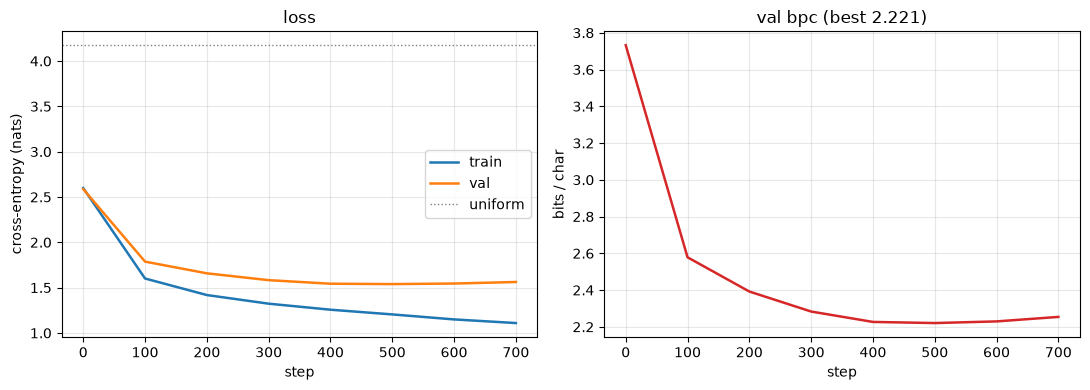

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history["step"], history["train"], lw=1.8, label="train")
axes[0].plot(history["step"], history["val"], lw=1.8, label="val")
axes[0].axhline(math.log(cfg.vocab_size), ls=":", c="grey", lw=1, label="uniform")
axes[0].set_xlabel("step"); axes[0].set_ylabel("cross-entropy (nats)")
axes[0].set_title("loss"); axes[0].legend(); axes[0].grid(alpha=.3)

axes[1].plot(history["step"], [v / math.log(2) for v in history["val"]], c="tab:red", lw=1.8)
axes[1].set_xlabel("step"); axes[1].set_ylabel("bits / char")
axes[1].set_title(f"val bpc (best {best_val/math.log(2):.3f})"); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

In [15]:
# a sample straight from the recurrent (O(1) per token) inference path
ids = torch.tensor([tokenizer.encode("What am i trained on?")], device=DEVICE)
print(tokenizer.decode(model.generate(ids, max_new_tokens=400, temperature=0.8, top_k=40)[0].tolist()))
model.train()
print(f"\ncheckpoint: {CKPT_PATH}  ({CKPT_PATH.stat().st_size/2**20:.1f} MiB)")
print("next: 02_mamba_inference.ipynb")

What am i trained on?

First Morloyal:
She is an art thou in his debt.

Clown:
Let's hold me not: yet, you are no hope had shows them
as a fury of her man intent his highway; he
they will refer these spends themselves: there is my husband
Did murder to thy hope, the bestering rights,
Shall be thy brave fellow accover.

POMPEY:
Sir, I am thy almost of mine adversion shall
A sign dislenses; then is not past me in
create

checkpoint: /home/kartik/Desktop/gkn/checkpoints/mamba_char.pt  (22.2 MiB)
next: 02_mamba_inference.ipynb


In [ ]:
# Side-by-side with every checkpoint in ./checkpoints, labelled by its own config.
# (A checkpoint from before this branch has no `state_schedule`, so it reads as "constant".)
rows = {}
for p in sorted(CKPT_DIR.glob("mamba_char*.pt")):
    c = torch.load(p, map_location="cpu", weights_only=False)
    cf = MambaConfig.from_dict(c["config"])
    rows[cf.state_schedule] = (cf.d_states, c["history"]["step"][-1] + 1, c["step"],
                               c["val_loss"], MambaLM(cf).num_parameters())

print(f"{'schedule':>9} | {'N per layer':>26} | {'params':>9} | {'ran':>5} | "
      f"{'best@':>6} | {'val':>7} | {'bpc':>6}")
print("-" * 90)
for sched, (dims, ran, best, vl, npar) in rows.items():
    print(f"{sched:>9} | {str(dims):>26} | {npar:>9,} | {ran:>5} | {best:>6} | "
          f"{vl:>7.4f} | {vl/math.log(2):>6.3f}")

if "constant" in rows and "linear" in rows:
    if rows["constant"][1] != rows["linear"][1]:
        print(f"\n!! different step counts ({rows['constant'][1]} vs {rows['linear'][1]}) - "
              f"not a fair comparison yet; re-run the shorter one to match.")
    d = rows["linear"][3] - rows["constant"][3]
    print(f"\nlinear - constant = {d:+.4f} nats ({d/math.log(2):+.4f} bits/char) "
          f"at an identical parameter count.")
    print("negative = moving the state budget down the stack wins.")
else:
    missing = "linear" if "constant" in rows else "constant"
    print(f"\n{missing!r} has not been trained yet. Set STATE_SCHEDULE = {missing!r} in "
          f"section 4,\nre-run from there, and this cell fills in the comparison.")

---
### Things worth trying

* **The other schedule** — flip `STATE_SCHEDULE` and re-run from section 4; the comparison
  cell above then prints both. Reversing the ramp (widest state first) is the natural
  control: if `"linear"` wins but reversed loses, placement really is what mattered, not
  just having non-uniform $N$.
* **Steeper or flatter ramps** — `state_dims` spends the budget on $N_l \propto (l+1)$.
  A gentler ramp (e.g. $N_l \propto l + 4$) or a step function are one line each.
* **Longer context** — cost is linear in $L$, so `SEQ_LEN=1024` costs ~4×, not ~16× as
  attention would. Per §4.3.2 quality should improve monotonically with context, and it is
  where a depth-varying budget should matter most.
* **Raise the budget** — $\bar N:16\to64$ grows the effective state 4× for few extra
  parameters; §4.6 shows that is where selectivity pays.
* **Ablate selectivity** — make $\Delta, B, C$ constant over time and you are back to an
  LTI S4-style model. The loss gap *is* the paper's central claim.
* **The real kernels** — `pip install mamba-ssm causal-conv1d` swaps in the hand-written
  fused CUDA scan. Same math, much faster.